In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D
import warnings
warnings.filterwarnings('ignore')

In [2]:
#load the dataset from google drive
file_id = "14tgk367vHqIREevhMyJYcY1BX0pGKkiz"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

# Load the dataset without a header. The previous attempt suggested a semicolon delimiter.
df = pd.read_csv(url, header=None, sep=',')

print("✅ Data loaded without headers")
print("Shape:", df.shape)
display(df.head())

✅ Data loaded without headers
Shape: (569, 32)


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
# Assign new column names.


# Generate placeholder column names based on the number of columns in the DataFrame
new_column_names = ['ID','Diagnosis','radius_mean','texture_mean','perimeter_mean',
                    'area_mean','smoothness_mean','compactness_mean','concavity_mean','concave_points_mean',
                    'symmetry_mean','fractal_dimension_mean','radius_se','texture_se','perimeter_se',
                    'area_se','smoothness_se','compactness_se','concavity_se','concave_points_se',
                    'symmetry_se','fractal_dimension_se','radius_worst','texture_worst','perimeter_worst',
                    'area_worst','smoothness_worst','compactness_worst','concavity_worst','concave_points_worst',
                    'symmetry_worst','fractal_dimension_worst']
df.columns = new_column_names

print("✅ Column names assigned")
display(df.head())

✅ Column names assigned


,ID,Diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
print("Displaying the 'Diagnosis' column (second column):")
display(df['Diagnosis'].head())

print("\nFull value counts for the 'Diagnosis' column:")
print(df['Diagnosis'].value_counts(dropna=False))

Displaying the 'Diagnosis' column (second column):


,Diagnosis
0,M
1,M
2,M
3,M
4,M



Full value counts for the 'Diagnosis' column:
Diagnosis
B    357
M    212
Name: count, dtype: int64


In [5]:
# Convert all into numerical
# Replace 'M' with 1 and 'B' with 0 in the 'Diagnosis' column
df['Diagnosis'] = df['Diagnosis'].map({'M': 1, 'B': 0})

print("✅ 'Diagnosis' column encoded: 'M' = 1, 'B' = 0")
display(df.head())
print(df['Diagnosis'].value_counts(dropna=False))

✅ 'Diagnosis' column encoded: 'M' = 1, 'B' = 0


,ID,Diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Diagnosis
0    357
1    212
Name: count, dtype: int64


In [6]:
# Remove non-feature columns
df = df.drop(columns=['ID']) if 'ID' in df.columns else df

# Encode target variable(Label)
label_enc = LabelEncoder()
df['Diagnosis'] = label_enc.fit_transform(df['Diagnosis'])  # M=1, B=0

print("✅ Data preprocessing complete\n")

# Check for missing values (Null Values)
print(df.isnull().sum())

✅ Data preprocessing complete

Diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave_points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave_points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave_points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64


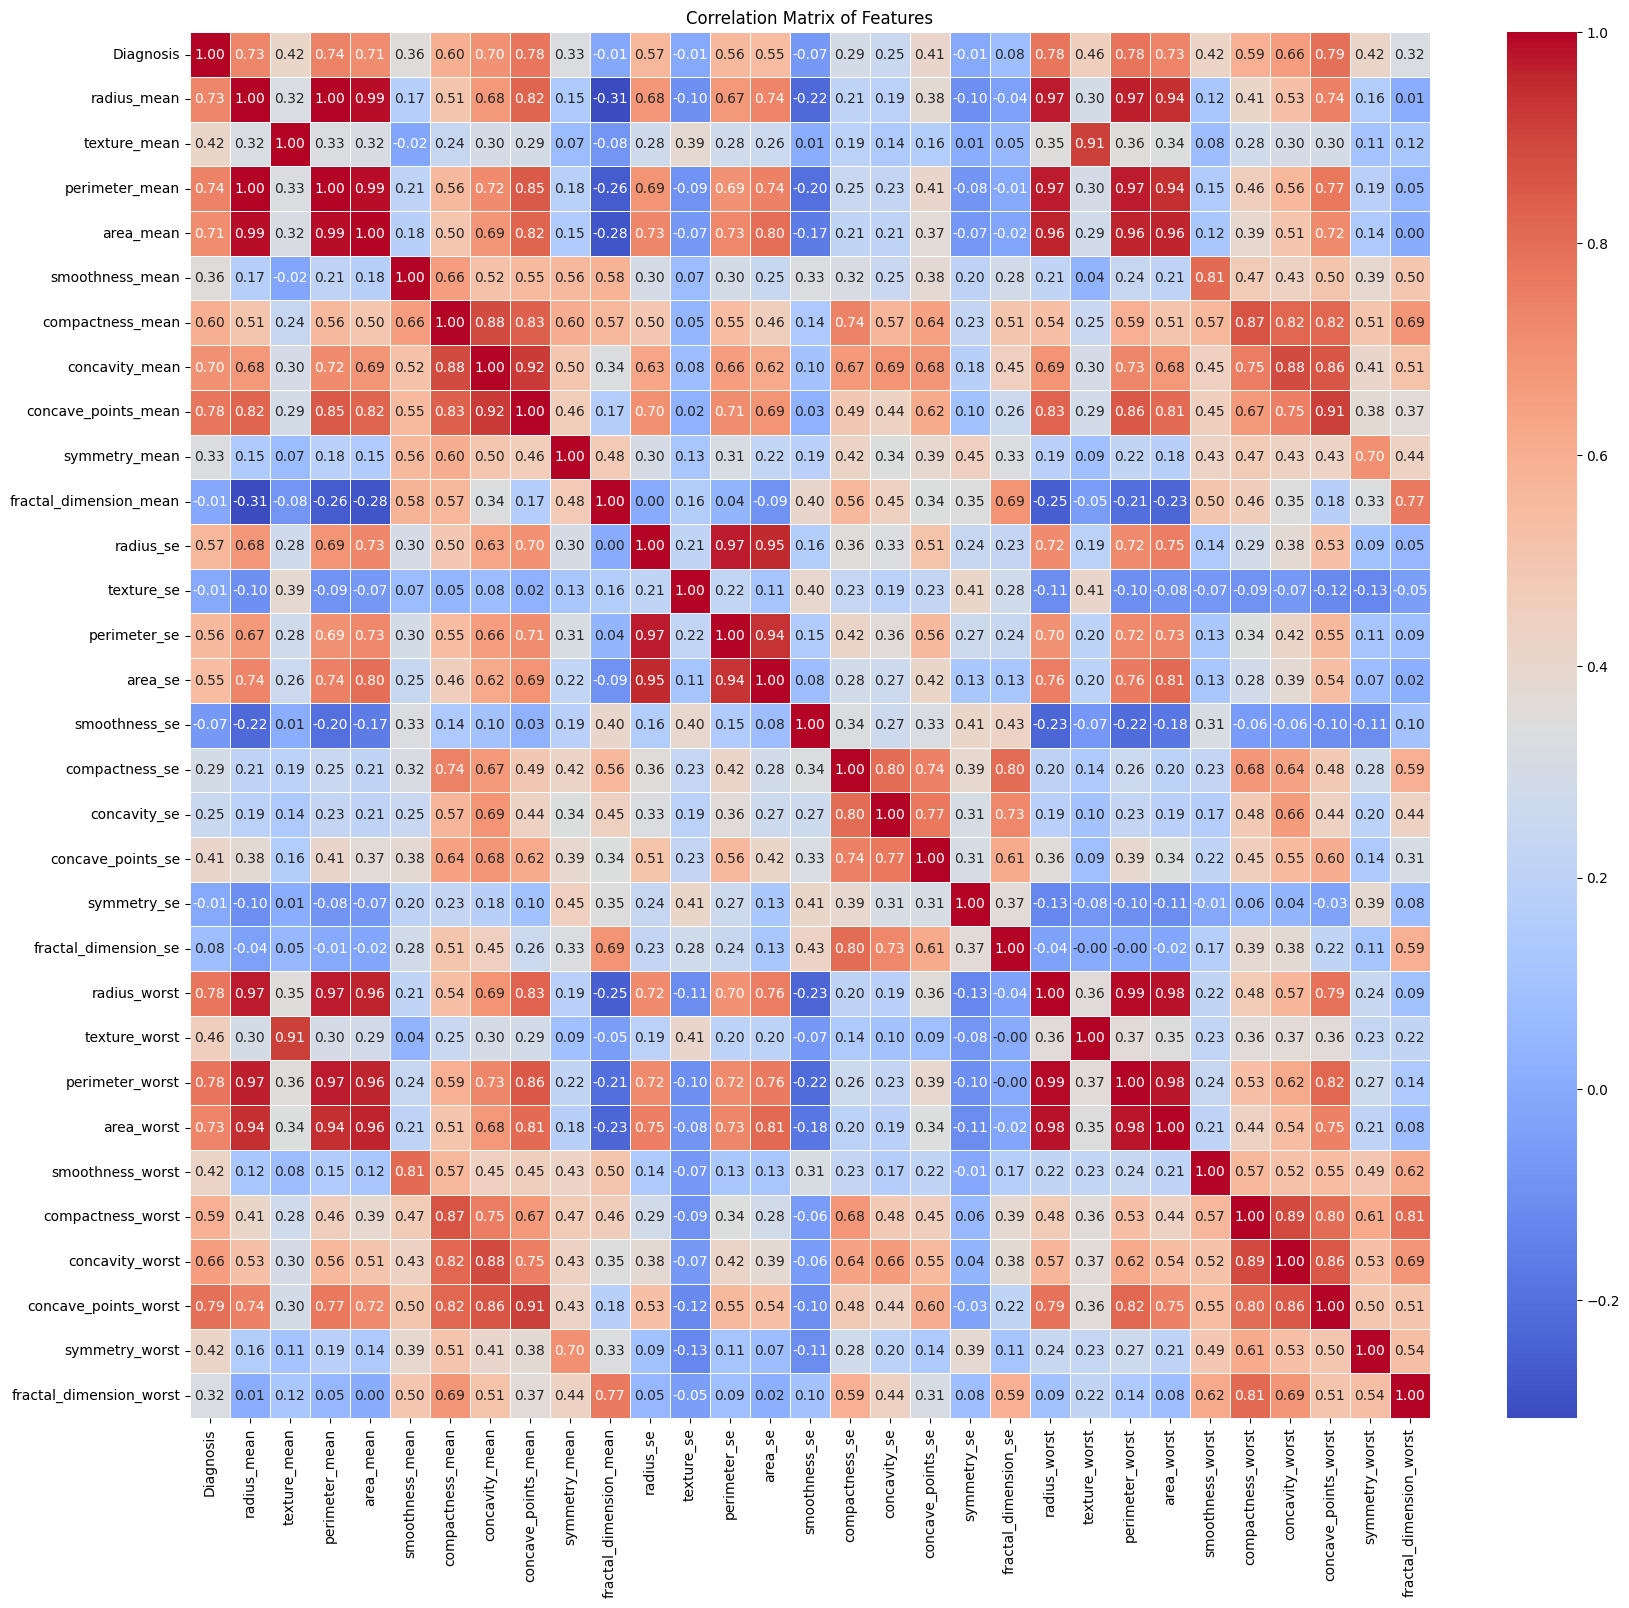

In [7]:
# Calculate the correlation matrix
correlation_matrix = df.corr()

# Plotting the heatmap
plt.figure(figsize=(20, 18))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Features')
plt.show()


Train set - Benign: 286, Malignant: 169
Test set  - Benign: 71, Malignant: 43



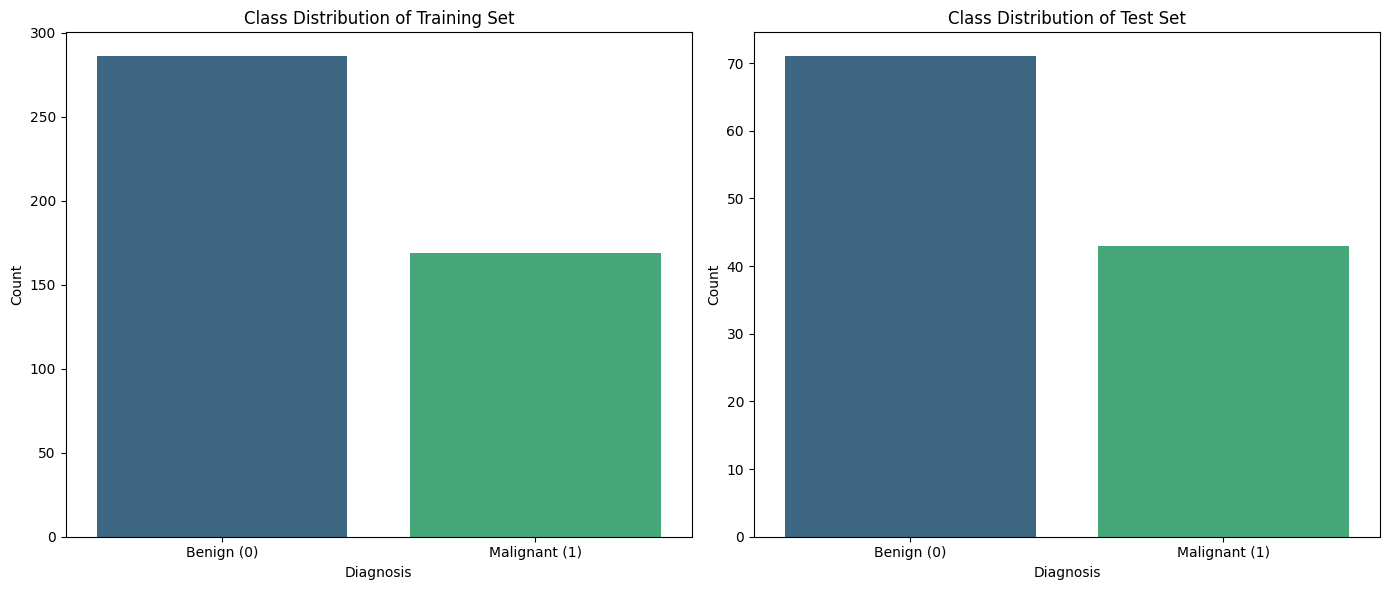

In [8]:
#Define the X and y
X = df.drop('Diagnosis', axis=1)
y = df['Diagnosis']

#Devide the dataset to train and test dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Check the Number of data devided into two classes in train and test dataset
print('='*30)
print(f"\nTrain set - Benign: {sum(y_train==0)}, Malignant: {sum(y_train==1)}")
print(f"Test set  - Benign: {sum(y_test==0)}, Malignant: {sum(y_test==1)}\n")
print('='*30)

# Visualize class distribution for both train and test sets
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.countplot(x=y_train, palette='viridis', ax=axes[0])
axes[0].set_title('Class Distribution of Training Set')
axes[0].set_xticks([0,1])
axes[0].set_xticklabels(['Benign (0)', 'Malignant (1)'])
axes[0].set_xlabel('Diagnosis')
axes[0].set_ylabel('Count')

sns.countplot(x=y_test, palette='viridis', ax=axes[1])
axes[1].set_title('Class Distribution of Test Set')
axes[1].set_xticks([0,1])
axes[1].set_xticklabels(['Benign (0)', 'Malignant (1)'])
axes[1].set_xlabel('Diagnosis')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()


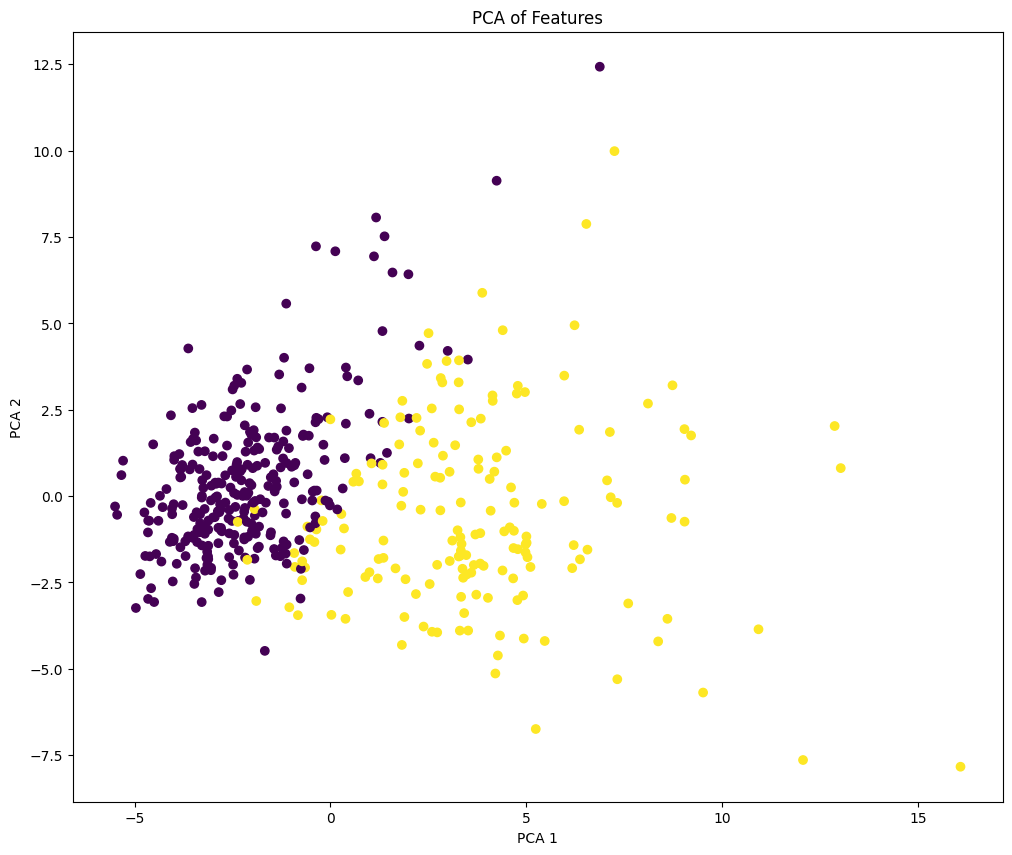

In [9]:
# Using PCA to visualize feature importance
features = df.drop('Diagnosis', axis=1)
scaler = StandardScaler()
features_scaled = scaler.fit_transform(X_train)

#Assgning PCA only for visualization
pca = PCA()
principal_components = pca.fit_transform(features_scaled)

plt.figure(figsize=(12, 10))
plt.scatter(principal_components[:, 0], principal_components[:, 1], c=y_train)
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('PCA of Features')
plt.show()


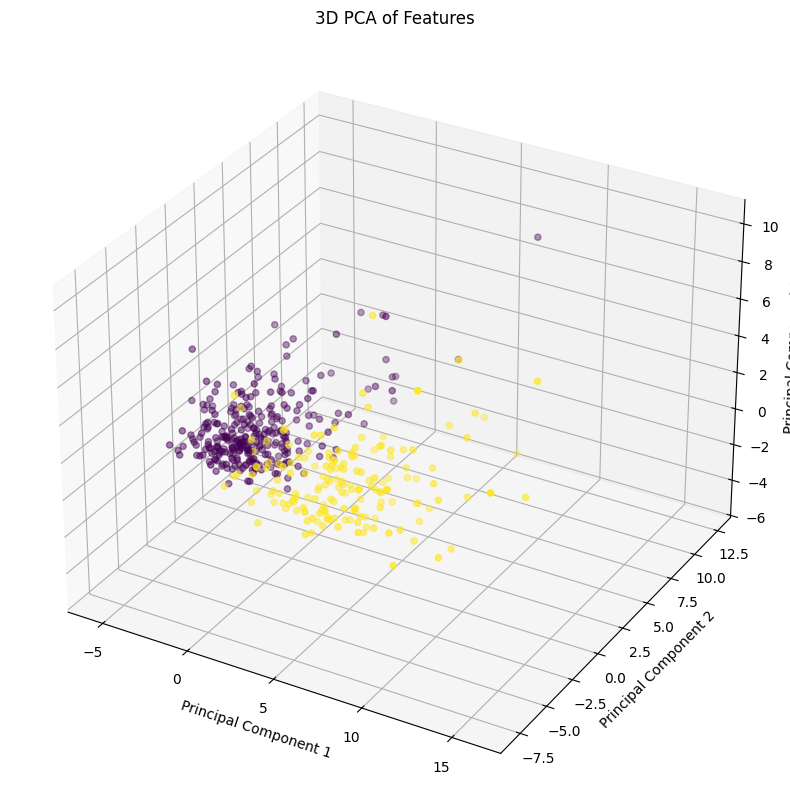

In [10]:
#Display the 3D PCA visualization
pca = PCA()
principal_components = pca.fit_transform(features_scaled)

# 3D plot
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(principal_components[:, 0], principal_components[:, 1], principal_components[:, 2], c=y_train, cmap='viridis')
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('3D PCA of Features')
plt.show()

In [11]:
#Classification model training

#Use pipelines for each model to aviod the data leakage
from sklearn.pipeline import Pipeline

#Logistic regression
lr_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000))
])

lr_pipeline.fit(X_train, y_train)
lr_pred = lr_pipeline.predict(X_test)

#Support Vector Machine
svm_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', probability=True))
])

svm_pipeline.fit(X_train, y_train)
svm_pred = svm_pipeline.predict(X_test)

#Random Forest
rf_pipeline = Pipeline(steps=[
    ('clf', RandomForestClassifier(n_estimators=200, random_state=42))
])

rf_pipeline.fit(X_train, y_train)
rf_pred = rf_pipeline.predict(X_test)


In [12]:
for model_name, y_pred in [('lr.pipeline', lr_pred), ('svm_pipeline', svm_pred), ('rf_pipeline', rf_pred)]:
    print(f"---{model_name}---")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred))

---lr.pipeline---
Accuracy: 0.9736842105263158
Confusion Matrix:
 [[70  1]
 [ 2 41]]
              precision    recall  f1-score   support

           0       0.97      0.99      0.98        71
           1       0.98      0.95      0.96        43

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

---svm_pipeline---
Accuracy: 0.9824561403508771
Confusion Matrix:
 [[71  0]
 [ 2 41]]
              precision    recall  f1-score   support

           0       0.97      1.00      0.99        71
           1       1.00      0.95      0.98        43

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

---rf_pipeline---
Accuracy: 0.9649122807017544
Confusion Matrix:
 [[70  1]
 [ 3 40]]
              precision    recall  f1-score   support

           0       0.96      0.99  

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Using the predictions from the previous model training
models = [
    ('Logistic Regression', lr_pred),
    ('Random Forest', rf_pred),
    ('SVM', svm_pred)
]

for model_name, y_pred in models:
    print(f"--- {model_name} ---")

    # Accuracy
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Accuracy: {accuracy:.4f}")

    # Precision (weighted average)
    precision = precision_score(y_test, y_pred, average='weighted')
    print(f"Precision (weighted): {precision:.4f}")

    # Recall (weighted average)
    recall = recall_score(y_test, y_pred, average='weighted')
    print(f"Recall (weighted): {recall:.4f}")

    # F1 Score (weighted average)
    f1 = f1_score(y_test, y_pred, average='weighted')
    print(f"F1 Score (weighted): {f1:.4f}")
    print("\n" + "-" * 30 + "\n")

--- Logistic Regression ---
Accuracy: 0.9737
Precision (weighted): 0.9737
Recall (weighted): 0.9737
F1 Score (weighted): 0.9736

------------------------------

--- Random Forest ---
Accuracy: 0.9649
Precision (weighted): 0.9652
Recall (weighted): 0.9649
F1 Score (weighted): 0.9647

------------------------------

--- SVM ---
Accuracy: 0.9825
Precision (weighted): 0.9829
Recall (weighted): 0.9825
F1 Score (weighted): 0.9824

------------------------------



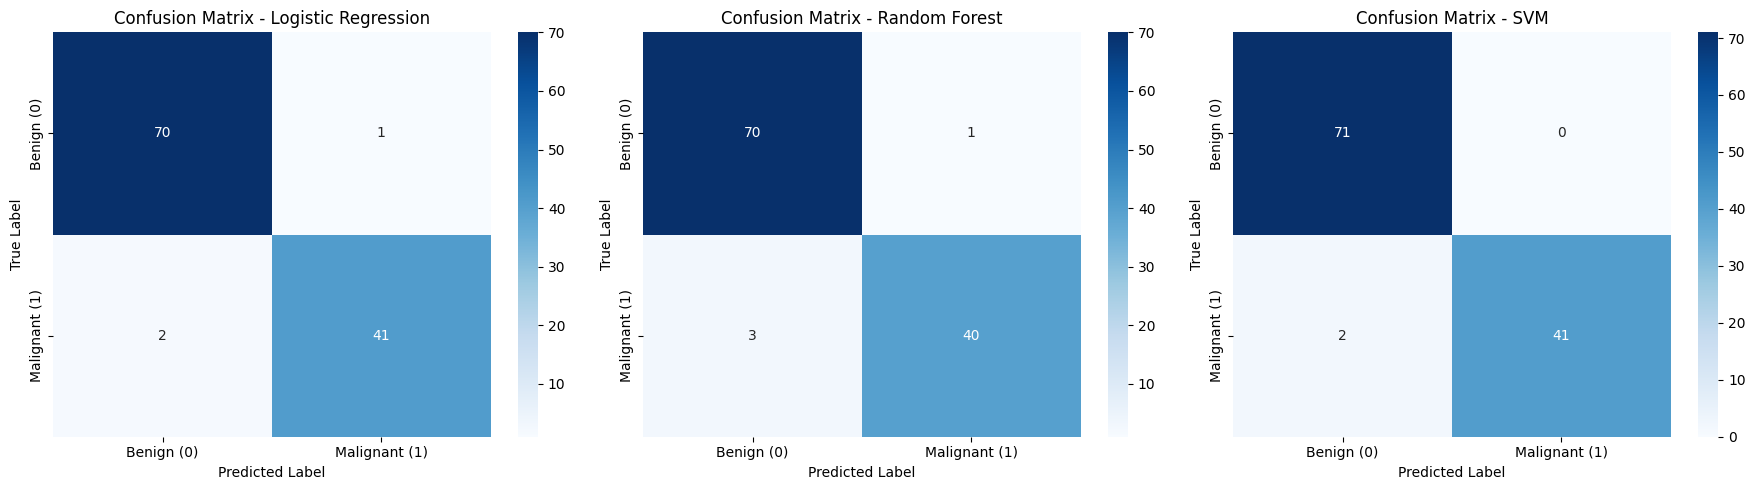

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = {
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred,
    "SVM": svm_pred
}


for i, (model_name, y_pred) in enumerate(models.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Benign (0)', 'Malignant (1)'],
                yticklabels=['Benign (0)', 'Malignant (1)'])
    axes[i].set_title(f'Confusion Matrix - {model_name}')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()

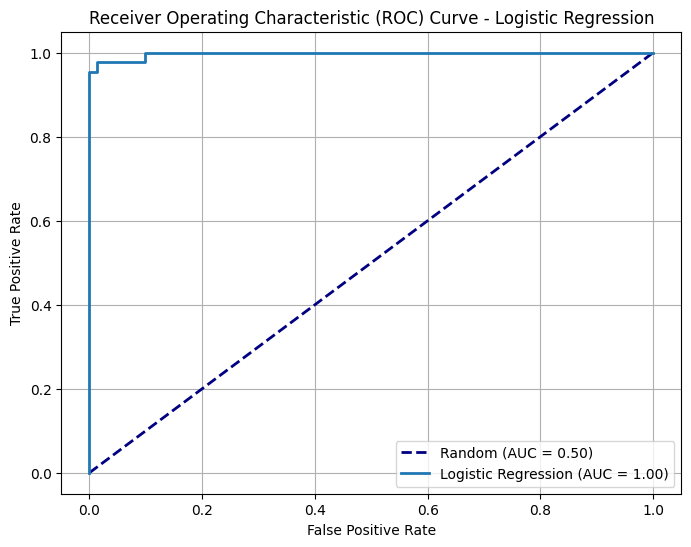

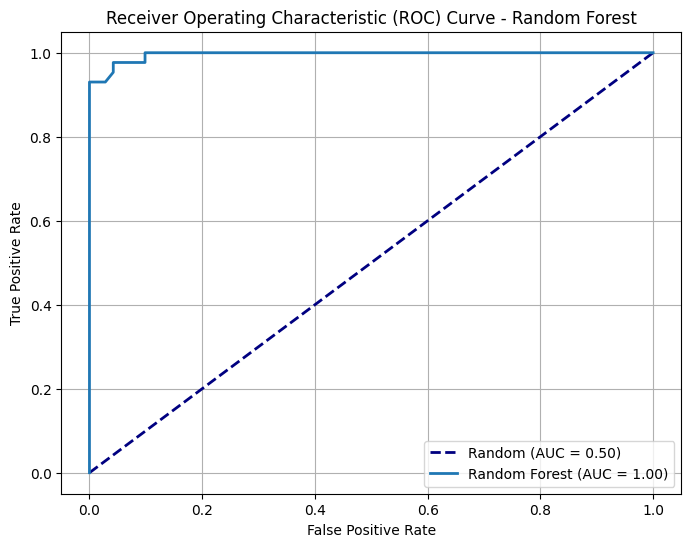

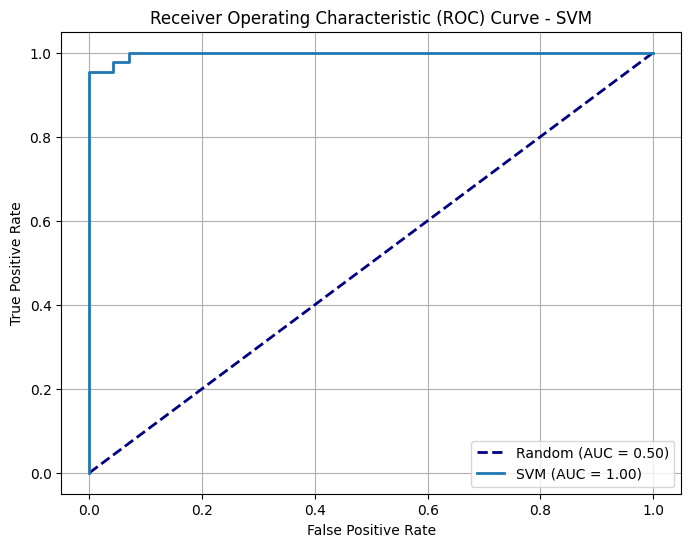

In [15]:
from sklearn.metrics import roc_curve, auc

# Get predicted probabilities for the positive class for each model
y_pred_prob_lr = lr_pipeline.predict_proba(X_test)[:, 1]
y_pred_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]
y_pred_prob_svm = svm_pipeline.predict_proba(X_test)[:, 1]

# Create a list of models with their probabilities and names
models_roc = [
    ('Logistic Regression', y_pred_prob_lr),
    ('Random Forest', y_pred_prob_rf),
    ('SVM', y_pred_prob_svm)
]

for model_name, y_pred_prob in models_roc:
    plt.figure(figsize=(8, 6))
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random (AUC = 0.50)')

    # Calculate ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
    roc_auc = auc(fpr, tpr)

    # Plot the ROC curve
    plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.2f})')


    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'Receiver Operating Characteristic (ROC) Curve - {model_name}')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()